# Практическая работа №4
## Регрессионная модель — Вариант B

**Датасет:** Auto MPG

**Цель работы:** обучить две модели линейной регрессии, сравнить наборы признаков, проверить мультиколлинеарность и оценить качество предсказаний.

**Целевая переменная:** mpg — количество миль, которое автомобиль проезжает на одном галлоне топлива. Чем выше значение, тем экономичнее автомобиль.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("../data/mpg.csv")

display(df.head())

print("Размер датасета:", df.shape)
print("\nПропущенные значения:")
print(df.isnull().sum())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


Размер датасета: (398, 9)

Пропущенные значения:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


### Первичный анализ данных

Датасет содержит характеристики автомобилей и показатель экономичности mpg.

Целевая переменная mpg является числовой, поэтому подходит для задачи регрессии.

В horsepower встречаются пропущенные значения. Для их обработки будет использоваться медиана, вычисленная только на обучающей выборке.

In [3]:
from sklearn.model_selection import train_test_split

features_all = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

X = df[features_all]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (318, 6)
Test: (80, 6)


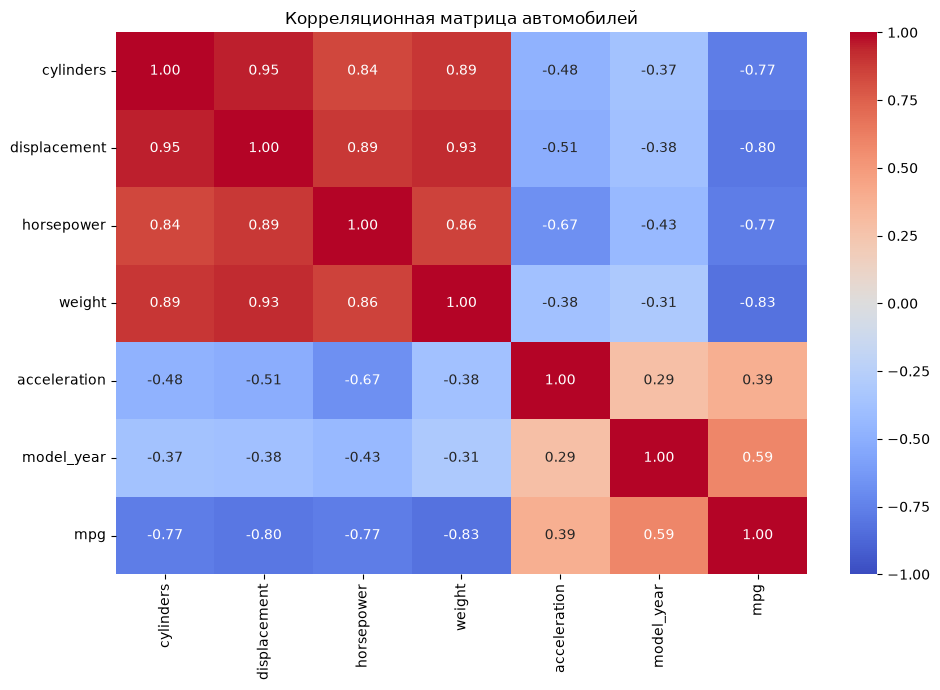

In [4]:
features_all = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

corr = X_train.assign(mpg=y_train).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица автомобилей")
plt.tight_layout()
plt.show()

In [5]:
feature_corr = X_train[features_all].corr().abs()

upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

strong_pairs = upper.stack()
strong_pairs = strong_pairs[strong_pairs > 0.8]

print("Сильные корреляции между признаками:")
print(strong_pairs.sort_values(ascending=False))

Сильные корреляции между признаками:
cylinders     displacement    0.951825
displacement  weight          0.929479
cylinders     weight          0.893808
displacement  horsepower      0.888972
horsepower    weight          0.855325
cylinders     horsepower      0.839187
dtype: float64


### Анализ корреляции

Между cylinders, displacement, horsepower и weight наблюдаются сильные положительные корреляции.

Это указывает на возможную мультиколлинеарность — ситуацию, когда несколько признаков содержат похожую информацию.

Для второй модели будет использован сокращённый набор признаков, чтобы проверить, можно ли получить сопоставимое качество с более простой моделью.

In [6]:
features_all = [
    "cylinders", "displacement",
    "horsepower", "weight",
    "acceleration", "model_year"
]

X = df[features_all]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (318, 6)
Test: (80, 6)


### Разделение данных

Данные разделены на две выборки:

- 80% — для обучения модели.
- 20% — для тестирования.

Разделение выполнено до предобработки и выбора признаков. Тестовая выборка не используется для расчёта статистик, обучения пайплайна или выбора модели.

In [7]:
def create_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

model_all = create_model()

model_all.fit(X_train, y_train)

pred_all = model_all.predict(X_test)

print("Первая модель обучена!")

Первая модель обучена!


In [8]:
mae_all = mean_absolute_error(y_test, pred_all)
mse_all = mean_squared_error(y_test, pred_all)
rmse_all = np.sqrt(mse_all)
r2_all = r2_score(y_test, pred_all)

print("MAE:", round(mae_all, 2))
print("MSE:", round(mse_all, 2))
print("RMSE:", round(rmse_all, 2))
print("R²:", round(r2_all, 3))

MAE: 2.47
MSE: 9.44
RMSE: 3.07
R²: 0.824


### Результат первой модели

Базовая модель обучена на шести числовых признаках.

MAE показывает, на сколько миль на галлон в среднем ошибаются предсказания модели. RMSE сильнее учитывает большие ошибки, а R² показывает качество предсказаний относительно базового прогноза средним значением.

Полученные метрики будут сравнены с результатами второй модели.

In [9]:
features_reduced = [
    "weight",
    "acceleration",
    "model_year"
]

model_reduced = create_model()

model_reduced.fit(
    X_train[features_reduced],
    y_train
)

pred_reduced = model_reduced.predict(
    X_test[features_reduced]
)

print("Вторая модель обучена!")

Вторая модель обучена!


In [10]:
results = pd.DataFrame({
    "Model": ["All features", "Reduced features"],
    "MAE": [
        mean_absolute_error(y_test, pred_all),
        mean_absolute_error(y_test, pred_reduced)
    ],
    "MSE": [
        mean_squared_error(y_test, pred_all),
        mean_squared_error(y_test, pred_reduced)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_all)),
        np.sqrt(mean_squared_error(y_test, pred_reduced))
    ],
    "R2": [
        r2_score(y_test, pred_all),
        r2_score(y_test, pred_reduced)
    ]
})

display(results.round(3))
best_index = results["RMSE"].idxmin()
best_model_name = results.loc[best_index, "Model"]

print("Модель с меньшим RMSE:", best_model_name)
print("Разница RMSE:",
      round(results["RMSE"].max() - results["RMSE"].min(), 3))

,Model,MAE,MSE,RMSE,R2
0,All features,2.467,9.44,3.072,0.824
1,Reduced features,2.460,9.41,3.068,0.825


Модель с меньшим RMSE: Reduced features
Разница RMSE: 0.005


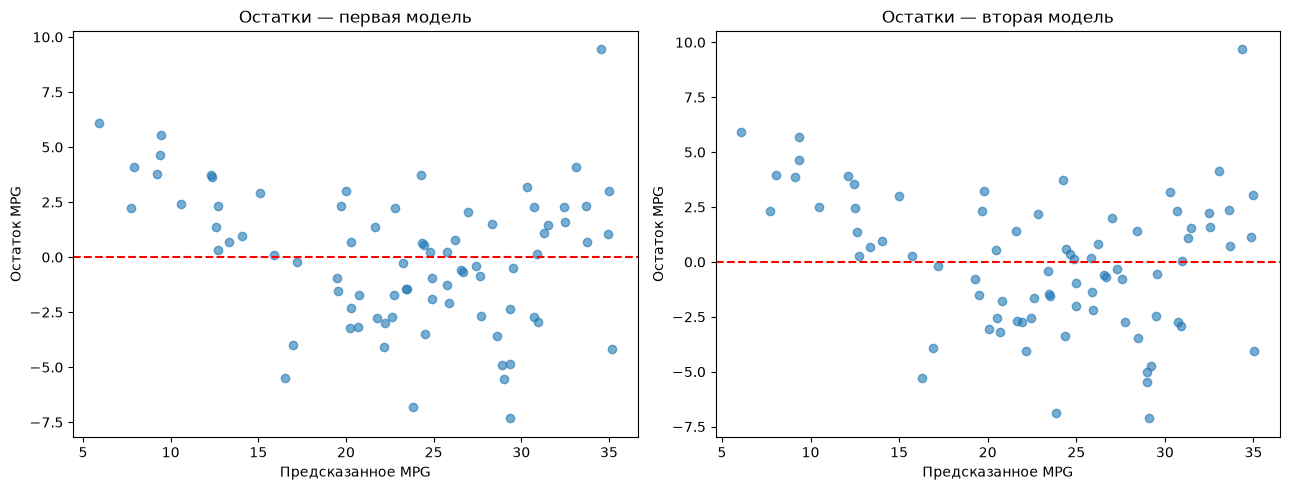

In [11]:
residuals_all = y_test - pred_all
residuals_reduced = y_test - pred_reduced

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(pred_all, residuals_all, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Остатки — первая модель")
axes[0].set_xlabel("Предсказанное MPG")
axes[0].set_ylabel("Остаток MPG")

axes[1].scatter(pred_reduced, residuals_reduced, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Остатки — вторая модель")
axes[1].set_xlabel("Предсказанное MPG")
axes[1].set_ylabel("Остаток MPG")

plt.tight_layout()
plt.show()

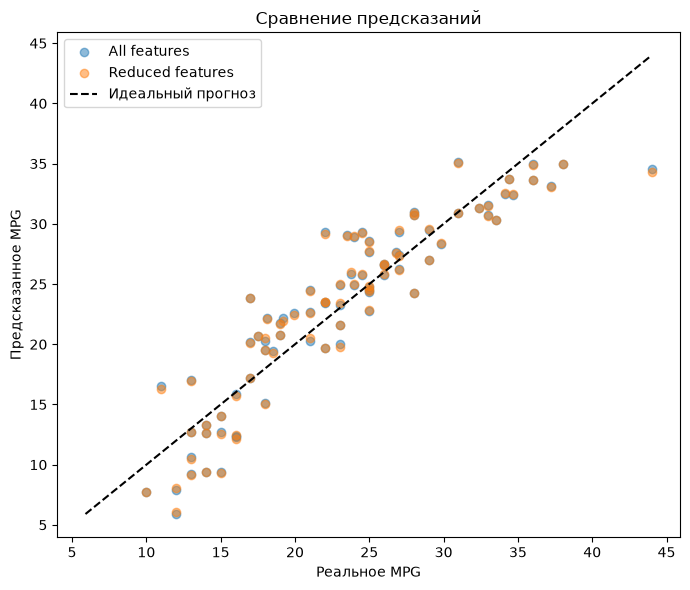

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test, pred_all,
    alpha=0.5, label="All features"
)

plt.scatter(
    y_test, pred_reduced,
    alpha=0.5, label="Reduced features"
)

limits = [
    min(y_test.min(), pred_all.min(), pred_reduced.min()),
    max(y_test.max(), pred_all.max(), pred_reduced.max())
]

plt.plot(limits, limits, "k--", label="Идеальный прогноз")

plt.xlabel("Реальное MPG")
plt.ylabel("Предсказанное MPG")
plt.title("Сравнение предсказаний")
plt.legend()
plt.tight_layout()
plt.show()

### Анализ графиков

Графики остатков помогают выявить систематические ошибки линейной регрессии. При отсутствии выраженного паттерна допущение о линейной зависимости выглядит более правдоподобным.

На графике предсказаний идеальным результатом является расположение точек вдоль диагональной линии.

Окончательный вывод о наличии систематического паттерна необходимо сделать после просмотра построенных графиков.

In [13]:
coef_table = pd.DataFrame({
    "Feature": features_all,
    "Coefficient": model_all.named_steps["regression"].coef_
})

coef_table["Abs_coefficient"] = coef_table["Coefficient"].abs()

display(
    coef_table.sort_values(
        "Abs_coefficient",
        ascending=False
    )
)

,Feature,Coefficient,Abs_coefficient
3,weight,-5.912040,5.912040
5,model_year,2.883008,2.883008
4,acceleration,0.222644,0.222644
1,displacement,0.164734,0.164734
0,cylinders,0.116123,0.116123
2,horsepower,0.107968,0.107968


## Итоговый отчёт

1. В практической работе использован датасет Auto MPG с числовой целевой переменной mpg.

2. Была проведена проверка мультиколлинеарности. Между характеристиками двигателя и весом автомобиля обнаружены сильные корреляции.

3. Созданы две модели LinearRegression. Первая использует шесть числовых признаков, вторая — три.

4. Для предобработки применён Pipeline с заполнением пропусков медианой и StandardScaler. Все преобразования обучаются только на тренировочной выборке.

5. Качество моделей оценивается по MAE, MSE, RMSE и R². Значения MAE и RMSE выражаются в милях на галлон (MPG), а MSE — в квадратных единицах MPG.

6. По графикам остатков проверяется наличие систематических ошибок, которые могут указывать на нарушение допущений линейной регрессии.

7. Окончательный выбор модели делается на основе полученных метрик, анализа остатков и сложности набора признаков.